# Pine vs eucalyptus

Cropin now wants plantations split into **pine** and **eucalyptus**. This notebook does the whole first
pass, in five steps:

1. **Labels.** Our data has no species, so we borrow it from WRI's *Spatial Database of Planted Trees*
   (SDPT v2.0). We look up the species of the SDPT polygon under each MapBiomas plantation point.
2. **Features.** We reuse the team's master feature table, AlphaEarth, and add simple **rotation**
   features from yearly Landsat NBR. Eucalyptus should be clear-cut every ~6–8 years, pine every ~12–25.
3. **Test.** Does any feature separate pine from eucalyptus? We check one feature at a time, then
   families in a model tested on regions it hasn't seen.
4. **Harvest cycle.** A closer look at the clearest known difference, with the team's harvest detector.
5. **Next step.** We draw a sample of points to label by hand ("gold" labels).

**Result in one line:** with SDPT's labels, nothing separates the two species except latitude, and the
harvest cycle doesn't either: almost no stand is cut at eucalyptus speed in the yearly data. Hand labels
come next.

**Metrics.**
- **AUC:** the chance that a random eucalyptus point scores higher than a random pine point (or lower,
  depending on the feature's direction). 0.5 means no separation and 1 is perfect.
- **95% CI:** bootstrap range of the AUC.
- **Holm p:** p-value corrected for testing many features at once.

Only MapBiomas reference points are used (public locations). The per-point labels stay in
`data/processed/`, which git ignores.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
warnings.filterwarnings("ignore", category=RuntimeWarning)

PD = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pine_detection/src").exists()) / "pine_detection"
sys.path.insert(0, str(PD / "src"))
import species_features as sf        # loading, SDPT lookup, rotation features, names
qa = sf.qa                           # the team's shared helpers (src/qc_analysis.py)
qa.set_style(); PAL = sf.PAL_SPECIES

## 1. Labels: SDPT species under each MapBiomas plantation point

SDPT polygons for southern Brazil come from Petersen et al. (2016), with **2013–14 imagery**. A point is
labelled only if it lies inside a pine or eucalyptus polygon. We use the **development split** and leave
the lockbox split untouched.

In [2]:
m = sf.add_sdpt(sf.load_master())        # master table (MapBiomas points) + SDPT species
plant = m[m.label == 1]
display(pd.crosstab(plant.species, plant.state, margins=True).rename_axis("SDPT species (all plantation points)"))

d = plant[(plant.split == "dev") & plant.species.isin(["pine", "eucalyptus"])].copy()
d["y"] = (d.species == "eucalyptus").astype(int)          # 1 = eucalyptus, 0 = pine
print(f"Analysis sample: {len(d)} points, {d.y.sum()} eucalyptus and {(d.y == 0).sum()} pine")

state,PR,RS,SC,All
SDPT species (all plantation points),,,,
acacia,0,7,0,7
eucalyptus,19,34,49,102
none,66,71,55,192
pine,73,41,85,199
unknown,9,1,3,13
All,167,154,192,513


Analysis sample: 245 points, 85 eucalyptus and 160 pine


## 2. Rotation features from yearly Landsat NBR (new)

NBR is high under a closed canopy and drops when trees are cut. For 2000–2020, a **clear-cut** is a fall
of at least 0.20 from the two previous years. A **partial drop** (0.08–0.20) is a thinning candidate.

In [3]:
nbr = sf.load_nbr(d.team_pid)
rot = sf.rotation_features(nbr).set_axis(d.index)
rot.loc[nbr.notna().sum(axis=1).to_numpy() < 15] = np.nan   # too few clear years: leave missing
d = d.join(rot)
display(d.groupby("species")[rot.columns.tolist()].median().T.round(1).rename_axis("median per point"))

species,eucalyptus,pine
median per point,,
rot_n_cuts,1.0,1.0
rot_med_interval,11.0,11.0
rot_years_since,12.0,11.0
rot_n_partial,1.0,1.0
rot_partial_per_cut,0.7,0.7


Medians are the same for both species, including **11 years between clear-cuts**. If the labels were
right, eucalyptus should be close to 6–8.

## 3a. One feature at a time

In [4]:
features = sf.master_feature_columns() + rot.columns.tolist() + ["lat", "lon"]
rows = []
for c in features:
    s = d[[c, "y"]].dropna()
    auc, lo, hi = qa.auc_ci(s.y, s[c])
    rows.append(dict(feature=sf.NAMES.get(c, c), AUC=auc, lo=lo, hi=hi,
                     higher_in="eucalyptus" if roc_auc_score(s.y, s[c]) >= 0.5 else "pine",
                     p=qa.mwu_test(s[s.y == 1][c], s[s.y == 0][c])))
uni = pd.DataFrame(rows)
uni["p_Holm"] = qa.holm(uni.p)
uni = uni.sort_values("AUC", ascending=False, ignore_index=True)
uni.head(10).round(3)

,feature,AUC,lo,hi,higher_in,p,p_Holm
0,latitude,0.645,0.571,0.720,pine,0.000,0.008
1,share of years below canopy,0.604,0.528,0.681,eucalyptus,0.007,0.300
2,NDVI 1985–89,0.572,0.502,0.650,pine,0.065,1.000
3,Hansen tree cover 2000,0.571,0.497,0.648,pine,0.065,1.000
4,B8A narrow NIR winter,0.569,0.492,0.644,eucalyptus,0.075,1.000
5,canopy height variability,0.568,0.488,0.648,pine,0.082,1.000
6,B6 red-edge winter,0.564,0.487,0.640,eucalyptus,0.098,1.000
7,LandTrendr vertices,0.555,0.478,0.630,pine,0.145,1.000
8,years of continuous forest,0.543,0.467,0.619,pine,0.272,1.000
9,NDVI winter,0.542,0.463,0.620,eucalyptus,0.276,1.000


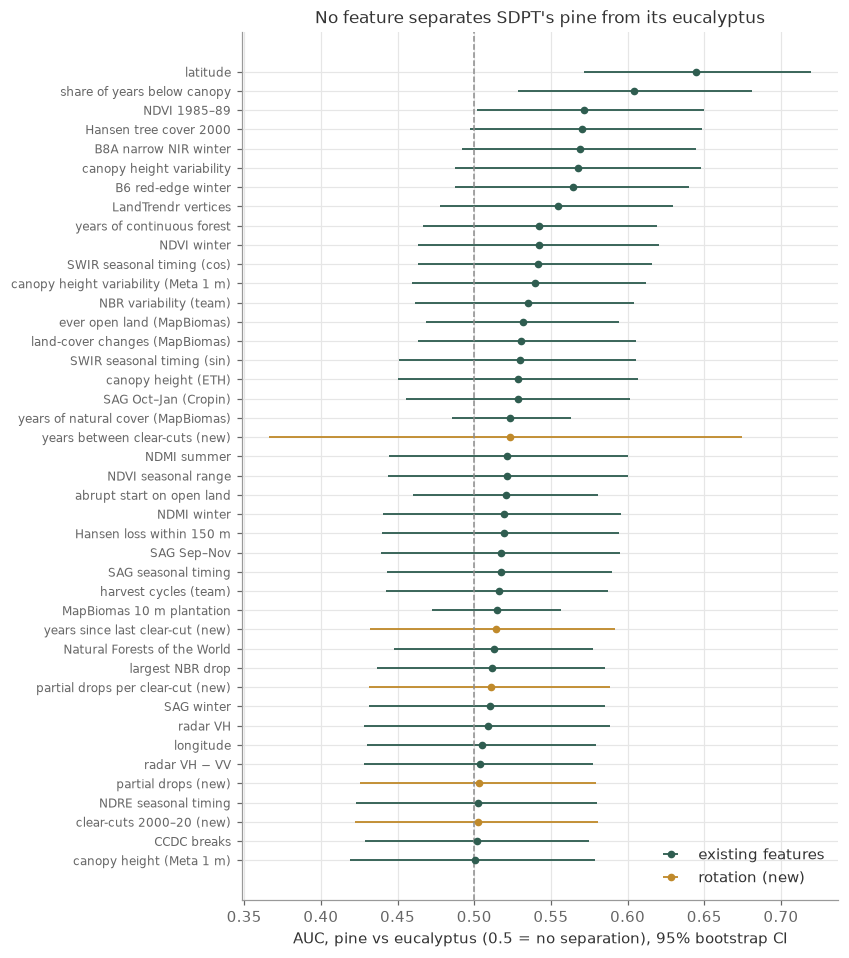

In [5]:
fig, ax = plt.subplots(figsize=(7, 0.22 * len(uni) + 1))
y = np.arange(len(uni))[::-1]
new = uni.feature.str.contains("new")
for k, col, lab in [(~new, PAL["pine"], "existing features"), (new, PAL["eucalyptus"], "rotation (new)")]:
    ax.errorbar(uni.AUC[k], y[k], xerr=[uni.AUC[k] - uni.lo[k], uni.hi[k] - uni.AUC[k]],
                fmt="o", ms=4, lw=1.2, color=col, label=lab)
ax.axvline(0.5, color=PAL["grey"], ls="--", lw=1)
ax.set_yticks(y); ax.set_yticklabels(uni.feature, fontsize=8)
ax.set_xlabel("AUC, pine vs eucalyptus (0.5 = no separation), 95% bootstrap CI")
ax.legend(loc="lower right"); ax.set_title("No feature separates SDPT's pine from its eucalyptus")
sf.savefig(fig, "pine_vs_eucalyptus_auc")

## 3b. Feature families in a model, tested on unseen regions

Each family goes into a logistic regression, with missing values filled by the median. The model is
trained on some regions and tested on the others (20 location blocks), and the AUC is averaged over
seeds 0–19.

In [6]:
def logit():
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=2000))

ae = [c for c in d.columns if c.startswith("ae_A")]
families = {"Geography (lat, lon)": ["lat", "lon"],
            "Master features": sf.master_feature_columns(),
            "Rotation (new)": rot.columns.tolist(),
            "AlphaEarth": ae,
            "Everything": sf.master_feature_columns() + rot.columns.tolist() + ae}
groups = qa.spatial_groups(d, k=20)
res = {name: qa.cv_evaluate(d[cols].to_numpy(float), d.y.to_numpy(), groups=groups, kind="spatial",
                            model_fn=logit)[0].auc for name, cols in families.items()}
pd.DataFrame({"mean AUC": {k: v.mean() for k, v in res.items()},
              "min": {k: v.min() for k, v in res.items()},
              "max": {k: v.max() for k, v in res.items()}}).round(2)

,mean AUC,min,max
"Geography (lat, lon)",0.54,0.50,0.57
Master features,0.51,0.46,0.54
Rotation (new),0.37,0.35,0.40
AlphaEarth,0.48,0.44,0.56
Everything,0.51,0.44,0.58


No family does clearly better than a coin flip. Values below 0.5 just mean that nothing learned in one
region carried over to the others.

## 3c. Is latitude just a regional effect? Same AUCs within each state

In [7]:
def auc_either_way(y, x):
    ok = x.notna()
    a = roc_auc_score(y[ok], x[ok])
    return max(a, 1 - a)

top = ["lat", "rh_s_frac_below_forest", "mm_B8A_win", "mm_B6_win"]
rows = []
for state, g in d.groupby("state"):
    row = {"state": f"{state} ({g.y.sum()} eucalyptus, {(g.y == 0).sum()} pine)"}
    row.update({sf.NAMES[c]: auc_either_way(g.y, g[c]) for c in top})
    rows.append(row)
pd.DataFrame(rows).set_index("state").round(2)

,latitude,share of years below canopy,B8A narrow NIR winter,B6 red-edge winter
state,,,,
"PR (17 eucalyptus, 58 pine)",0.74,0.62,0.61,0.60
"RS (31 eucalyptus, 30 pine)",0.68,0.58,0.67,0.66
"SC (37 eucalyptus, 72 pine)",0.63,0.66,0.51,0.52


Latitude still separates the species *within* each state, so SDPT's species sit in regional clusters.
The satellite features stay weak, and their AUCs change from state to state.

## 4. Focus on the harvest cycle

The harvest cycle is the clearest known difference between the two crops:
- **eucalyptus** is clear-cut every **6–8 years**, about 1.2–1.7 cuts per decade, and its canopy closes
  again within about 2 years;
- **pine** is clear-cut every **12–25 years**, about 0.4–0.8 cuts per decade, with thinnings in between.

Section 2 used a simple rule on 2000–2020. Here we use the team's own detector
(`combined_model/scripts/harvest_features.py`, a segmented fit of yearly NBR over 1985–2020), and
MapBiomas's yearly classes to know **how long** each point has been a plantation. Three checks:
- **4a.** Cycle measures vs SDPT species.
- **4b.** The same with other yearly series and cut thresholds, in case the detector is the problem.
- **4c.** Without any labels: do plantations fall into two cutting rhythms on their own?

In [8]:
hc_all = sf.team_harvest_features()        # all public points; prints the detector's two NBR levels
def cycle_table(pts):
    hc = hc_all.reindex(pts.team_pid).set_axis(pts.index)
    age = sf.plantation_years(pts.team_pid).set_axis(pts.index)
    first = age.first_plant_year.clip(lower=1985)
    return pd.DataFrame({
        "cuts since 1985": hc.n_cuts,
        "cuts per decade as plantation": hc.n_cuts / ((2021 - first) / 10),
        "years to regrow after a cut": hc.regrow_years,
        "years since last cut": hc.years_since_last_cut.where(hc.n_cuts > 0),
        "years as plantation (MapBiomas)": age.n_plant_years}, index=pts.index)

cyc = cycle_table(d)
rows = []
for c in cyc.columns:
    s = pd.DataFrame({"x": cyc[c], "y": d.y}).dropna()
    auc, lo, hi = qa.auc_ci(s.y, s.x)
    rows.append({"measure": c, "median eucalyptus": s.x[s.y == 1].median(), "median pine": s.x[s.y == 0].median(),
                 "AUC": auc, "lo": lo, "hi": hi, "n": len(s)})
display(pd.DataFrame(rows).set_index("measure").round(2))

long_ = cyc["years as plantation (MapBiomas)"] >= 20
no_cut = (cyc["cuts since 1985"] == 0) & long_
print("Plantation for 20+ years but no cut detected since 1985: "
      f"{no_cut[d.y == 1].sum()} of {long_[d.y == 1].sum()} SDPT-eucalyptus, "
      f"{no_cut[d.y == 0].sum()} of {long_[d.y == 0].sum()} SDPT-pine")

Closed-canopy level (5th percentile at stable closed-canopy pixels): NBR 0.584  (from 1,342 pixels)
Open-land level (25th percentile at open-land pixels):              NBR 0.405  (from 79 pixels)


,median eucalyptus,median pine,AUC,lo,hi,n
measure,,,,,,
cuts since 1985,2.00,1.00,0.50,0.42,0.58,208
cuts per decade as plantation,0.56,0.56,0.52,0.43,0.60,208
years to regrow after a cut,1.71,2.11,0.54,0.46,0.63,156
years since last cut,8.00,11.00,0.53,0.45,0.62,167
years as plantation (MapBiomas),15.00,16.50,0.50,0.43,0.57,245


Plantation for 20+ years but no cut detected since 1985: 2 of 37 SDPT-eucalyptus, 6 of 69 SDPT-pine


### 4b. Is it the detector? Other yearly series and thresholds

A simple rule (section 2) on 1987–2020, counting cuts per decade as plantation, with five yearly series
(whole-year median, dry-season median, wet-season median, yearly maximum, NDVI) and three cut sizes. Each
cell is the AUC for SDPT pine vs eucalyptus.

In [9]:
first = sf.plantation_years(d.team_pid).first_plant_year.clip(lower=1987).to_numpy()
grid = {}
for name in ["nbr_median", "nbr_dry_median", "nbr_wet_median", "nbr_max", "ndvi_median"]:
    s = sf.load_series(d.team_pid, name)
    scale = 0.5 if name.startswith("ndvi") else 1.0       # NDVI varies about half as much as NBR
    for cut in [0.10, 0.15, 0.20]:
        r = sf.rotation_features(s, cut=cut * scale, thin=cut * scale / 2, start=1987, end=2020, min_gap=2)
        per_decade = pd.Series(r.rot_n_cuts.to_numpy() / ((2021 - first) / 10), index=d.index)
        grid[(name, f"drop ≥ {cut:.2f}")] = auc_either_way(d.y, per_decade)
pd.Series(grid).unstack().round(2).rename_axis("yearly series (NDVI drops halved)")

,drop ≥ 0.10,drop ≥ 0.15,drop ≥ 0.20
yearly series (NDVI drops halved),,,
nbr_dry_median,0.53,0.50,0.51
nbr_max,0.57,0.57,0.52
nbr_median,0.54,0.52,0.51
nbr_wet_median,0.52,0.50,0.52
ndvi_median,0.53,0.52,0.50


### 4c. Without labels: two cutting rhythms?

If plantations here were a mix of eucalyptus (fast) and pine (slow), and the yearly data could see the cuts,
cuts per decade should show **two humps** whatever SDPT says. We take every development-split plantation
point that has been a plantation for 20+ years (whatever its SDPT label), count how many fall in the range
expected for each crop, and plot the distribution.

166 long-standing plantation points (20+ years), share by cutting rate:


,% of points
cuts per decade as plantation,
< 0.4 (slower than pine),41.0
0.4–0.8 (pine),34.0
0.8–1.2 (in between),18.0
1.2–1.7 (eucalyptus),6.0
> 1.7 (faster),1.0


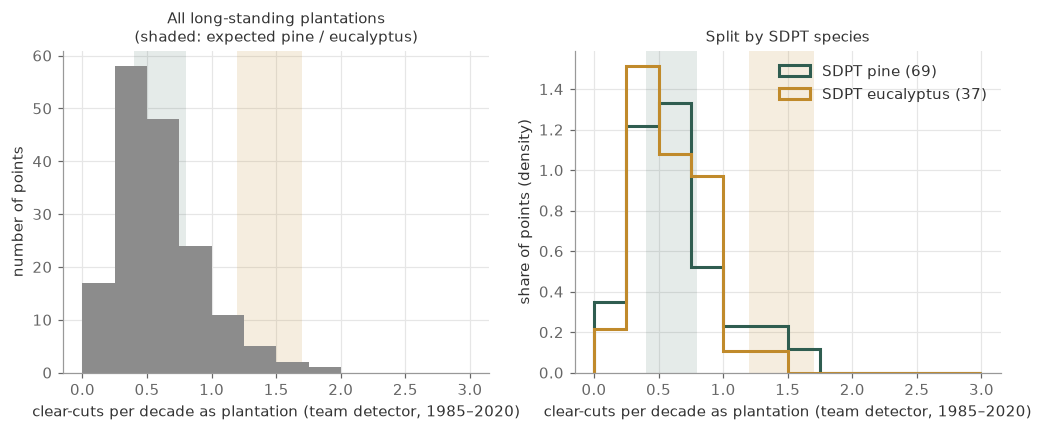

In [10]:
pd_dev = plant[plant.split == "dev"]
c_all = cycle_table(pd_dev)
k = c_all["years as plantation (MapBiomas)"] >= 20
x = c_all.loc[k, "cuts per decade as plantation"].dropna()
ranges = pd.cut(x, [-0.01, 0.39, 0.8, 1.19, 1.7, 99],
                labels=["< 0.4 (slower than pine)", "0.4–0.8 (pine)", "0.8–1.2 (in between)",
                        "1.2–1.7 (eucalyptus)", "> 1.7 (faster)"])
print(f"{len(x)} long-standing plantation points (20+ years), share by cutting rate:")
display((ranges.value_counts(normalize=True, sort=False) * 100).round(0).rename("% of points").to_frame())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharex=True)
bins = np.arange(0, 3.01, 0.25)
for ax in axes:
    ax.axvspan(0.4, 0.8, color=PAL["pine"], alpha=0.12, lw=0)
    ax.axvspan(1.2, 1.7, color=PAL["eucalyptus"], alpha=0.15, lw=0)
    ax.set_xlabel("clear-cuts per decade as plantation (team detector, 1985–2020)")
axes[0].hist(x, bins=bins, color=PAL["grey"])
axes[0].set_ylabel("number of points")
axes[0].set_title("All long-standing plantations\n(shaded: expected pine / eucalyptus)", fontsize=10)
sp = pd_dev.loc[x.index, "species"]
for s_name in ["pine", "eucalyptus"]:
    axes[1].hist(x[sp == s_name], bins=bins, density=True, histtype="step", lw=2,
                 color=PAL[s_name], label=f"SDPT {s_name} ({(sp == s_name).sum()})")
axes[1].set_ylabel("share of points (density)")
axes[1].set_title("Split by SDPT species", fontsize=10); axes[1].legend()
sf.savefig(fig, "pine_vs_eucalyptus_harvest_cycle")

**What the harvest cycle shows:**
- **No difference between SDPT's species (4a, 4b).** Every cycle measure has an AUC of 0.50–0.57, whichever
  series or cut size is used. Regrowth is a little faster for SDPT eucalyptus (1.7 vs 2.1 years), but within
  the noise.
- **Almost nothing is cut at eucalyptus speed (4c).** Only about 7% of long-standing plantations show 1.2 or
  more cuts per decade. The distribution has a single hump, at pine speed or slower, and SDPT eucalyptus
  sits in the same hump as SDPT pine.

So the problem isn't only SDPT. Either eucalyptus is rare among these older stands, or **yearly Landsat
medians miss most eucalyptus cuts**: a stand cut and closed again within about 2 years barely moves a
median of about 6 images a year. The hand labels will tell which. If they find many eucalyptus stands, the
harvest cycle needs a denser time series (every Sentinel-2 or Landsat image, extracted in GEE) before it
can help.

## 5. Conclusion and next step

- **The labels are the likely problem.** Conifer and broadleaf canopies are known to differ in Sentinel-2
  data, and eucalyptus should have much shorter rotations. Yet SDPT's pine and eucalyptus look the same in
  every feature. Only latitude separates them, so SDPT seems right by region but not stand by stand. Its
  labels are 12 years old, with no accuracy assessment.
- **The yearly harvest cycle can't help yet.** It shows no species difference, and almost no stand looks
  like a 6–8-year eucalyptus rotation, so yearly medians probably miss fast cuts.
- **Next: hand labels.** The cell below draws 250 public MapBiomas points (seed 0) and writes blind
  labelling sheets and KML files to `data/processed/gold_sample/`.
  - **Batch 1 (135 points)** checks how often SDPT is right.
  - **Batch 2 (115 points)** adds points SDPT can't label.
  - The rules are in `pine_detection/docs/labelling_protocol.md`, and `pine_detection/gee/02_labelling_helper.js`
    is a viewer to help.

In [11]:
import make_gold_sample
key = make_gold_sample.main()

250 points written to data/processed/gold_sample/
batch               1    2  All
stratum                        
A_eucalyptus       50    0   50
A_pine             50    0   50
B_unmatched         0   80   80
C_forest_in_sdpt   35    0   35
D_other             0   20   20
E_control           0   15   15
All               135  115  250
state             PR  RS  SC
stratum                     
A_eucalyptus       9  17  24
A_pine            18  10  22
B_unmatched       27  30  23
C_forest_in_sdpt  12   6  17
D_other            9   8   3
E_control          5   5   5
